# Pima Indians Diabete Prediction

### Good to know
According to Wikipedia, The Pima (also known as the Akimel Oʼodham or Akimel Oʼotham, meaning "River People") are a group of Native Americans living primarily in central and southern Arizona (United States) as well as northwestern Mexico (Sonora and Chihuahua).

## 1. Import Libraries & load dataset

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

df = pd.read_csv("../data/pima-indians-diabetes.csv", header=None, names=["Pregnancies", "Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"])
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 2. Exploratory Data Analysis (EDA)

### 2.1 Descriptive Analysis

In [46]:
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

### 2.2 Data Visualization

#### 2.1 Outcome part

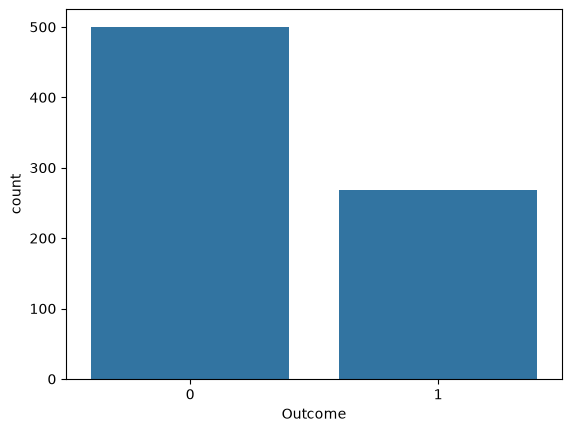

In [ ]:
# Distribution de la cible
sns.countplot(x="Outcome", data=df)
plt.show()

#### 2.2 Univariate Plots

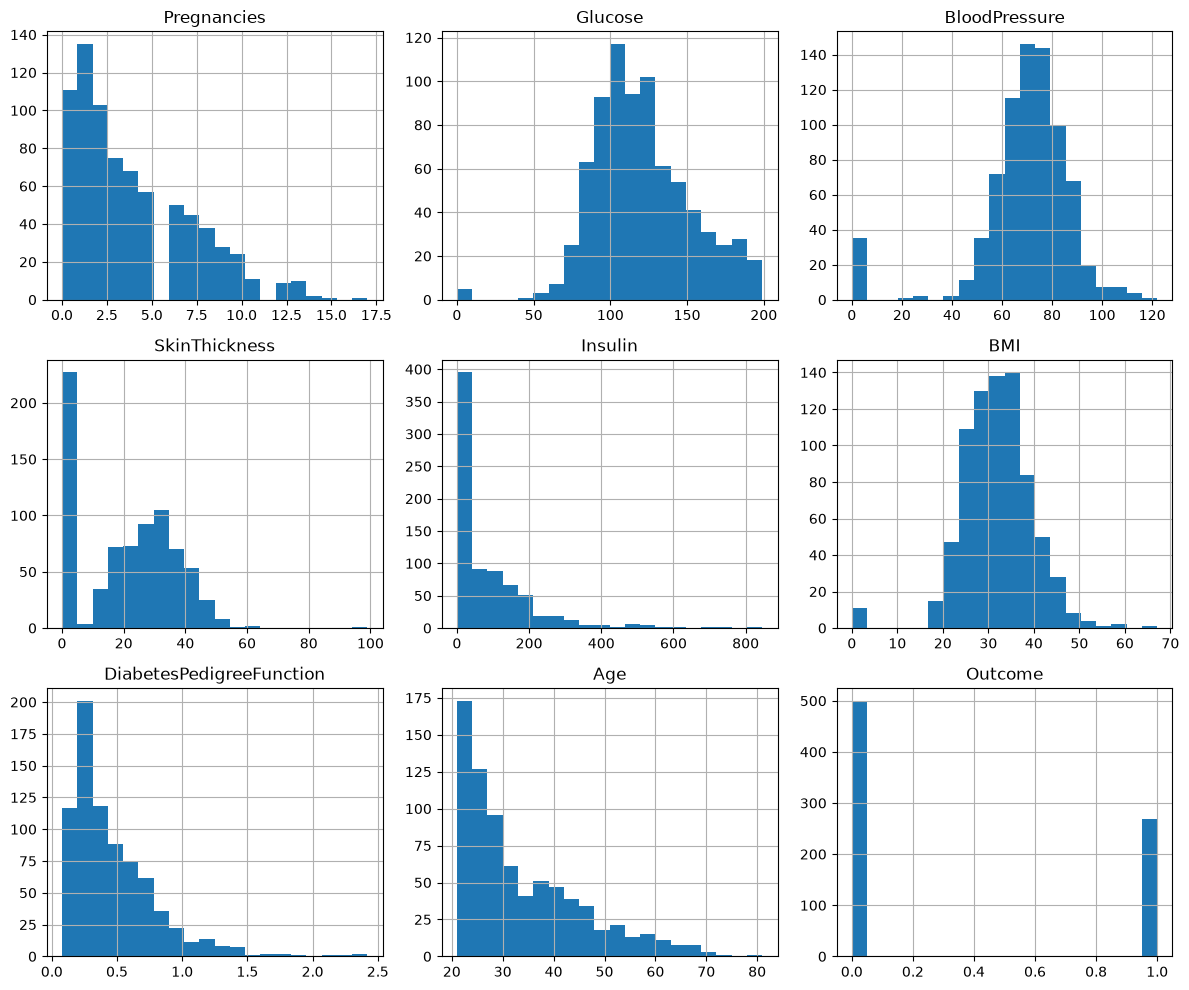

In [ ]:
# Histogrammes
df.hist(figsize=(12, 10), bins=20)
plt.tight_layout()
plt.show()

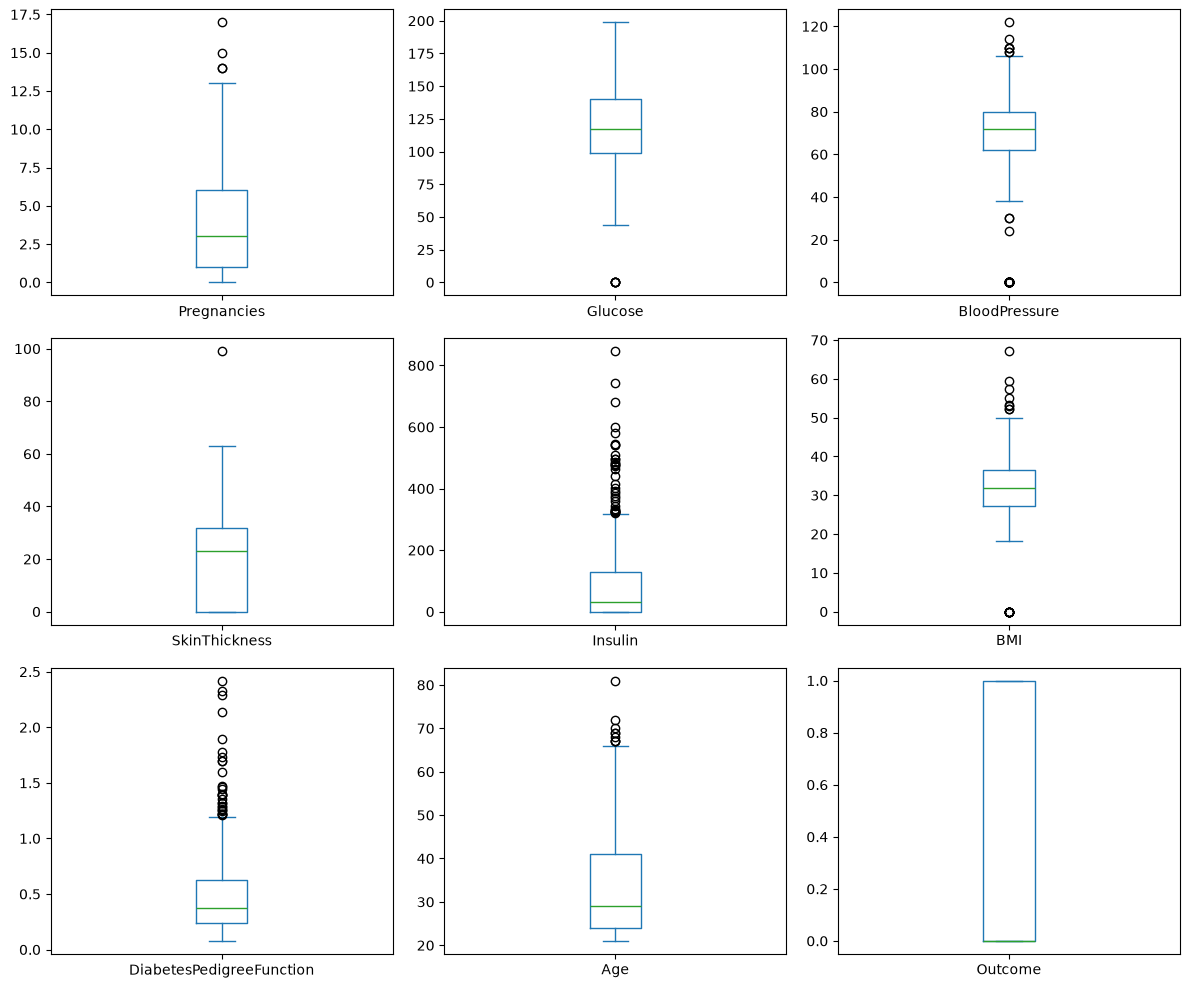

In [ ]:
# Box plots
df.plot(kind="box", subplots=True, layout=(3, 3), figsize=(12, 10))
plt.tight_layout()
plt.show()

#### 2.3 Multivariate Plots

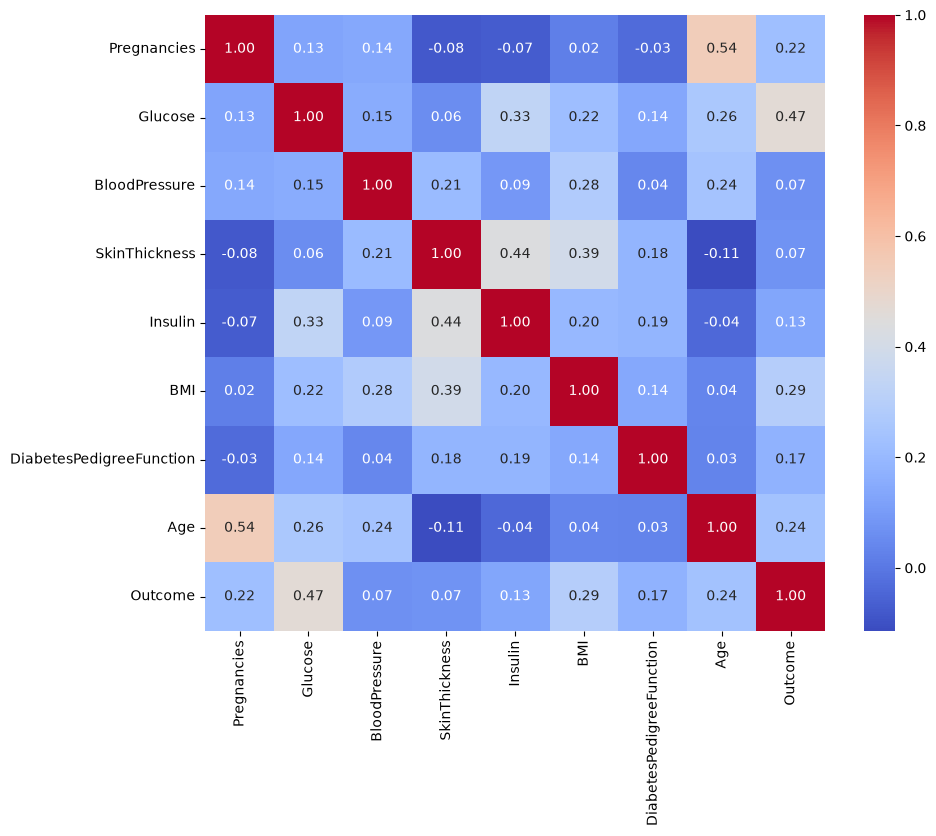

In [ ]:
# Corrélations
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.show()

## 3. Model Building

In [ ]:
# Colonnes où 0 est impossible
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan)
print(df.isnull().sum())

# Séparer X et y
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Split AVANT l'imputation (évite la fuite de données)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Imputation par la médiane
imputer = SimpleImputer(strategy="median")
X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)

# Standardisation (fit uniquement sur le train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
# train each model
log_reg = LogisticRegression()
log_reg.fit(X_train_scaled, y_train)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



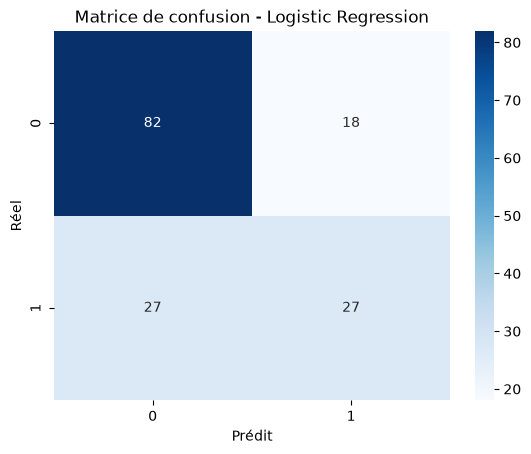

=== k-NN ===
              precision    recall  f1-score   support

           0       0.80      0.83      0.81       100
           1       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



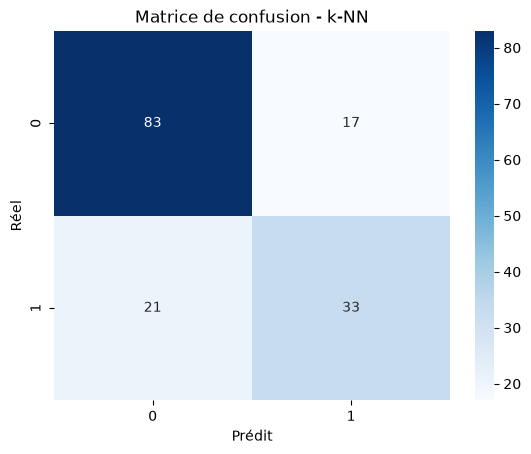

F1 LR : 0.5454545454545454 | F1 kNN : 0.6346153846153846


In [ ]:
# evaluate each model
def evaluer(model, nom):
    y_pred = model.predict(X_test_scaled)
    print(f"=== {nom} ===")
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
    plt.title(f"Matrice de confusion - {nom}")
    plt.xlabel("Prédit")
    plt.ylabel("Réel")
    plt.show()
    return f1_score(y_test, y_pred)

f1_lr = evaluer(log_reg, "Logistic Regression")
f1_knn = evaluer(knn, "k-NN")
print("F1 LR :", f1_lr, "| F1 kNN :", f1_knn)

=== Random Forest ===
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.61      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.74      0.74       154
weighted avg       0.77      0.77      0.77       154



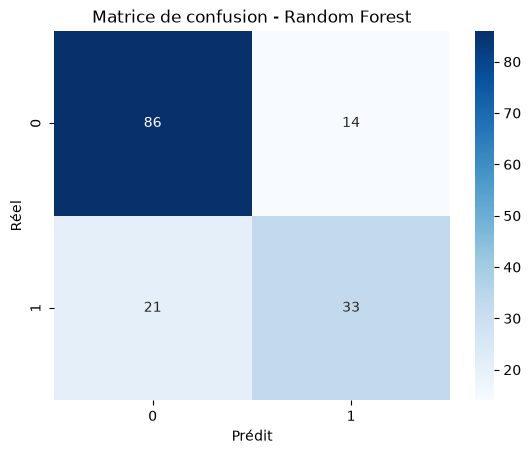

=== XGBoost ===
              precision    recall  f1-score   support

           0       0.80      0.86      0.83       100
           1       0.70      0.59      0.64        54

    accuracy                           0.77       154
   macro avg       0.75      0.73      0.73       154
weighted avg       0.76      0.77      0.76       154



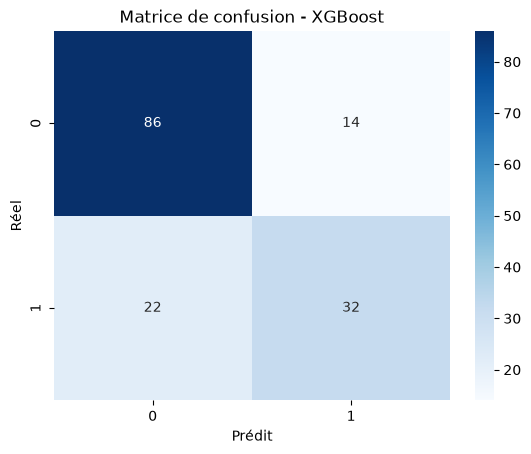

                Modèle        F1
2        Random Forest  0.653465
3              XGBoost  0.640000
1                 k-NN  0.634615
0  Logistic Regression  0.545455


In [ ]:
# Random Forest and XGBoost
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

xgb = XGBClassifier(eval_metric="logloss", random_state=42)
xgb.fit(X_train_scaled, y_train)

f1_rf = evaluer(rf, "Random Forest")
f1_xgb = evaluer(xgb, "XGBoost")

resultats = pd.DataFrame({
    "Modèle": ["Logistic Regression", "k-NN", "Random Forest", "XGBoost"],
    "F1": [f1_lr, f1_knn, f1_rf, f1_xgb],
})
print(resultats.sort_values("F1", ascending=False))

Meilleurs paramètres : {'max_depth': None, 'min_samples_split': 2, 'n_estimators': 200}
Meilleur score CV : 0.6435009818016804
=== Random Forest optimisé ===
              precision    recall  f1-score   support

           0       0.79      0.84      0.81       100
           1       0.66      0.57      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.71       154
weighted avg       0.74      0.75      0.74       154



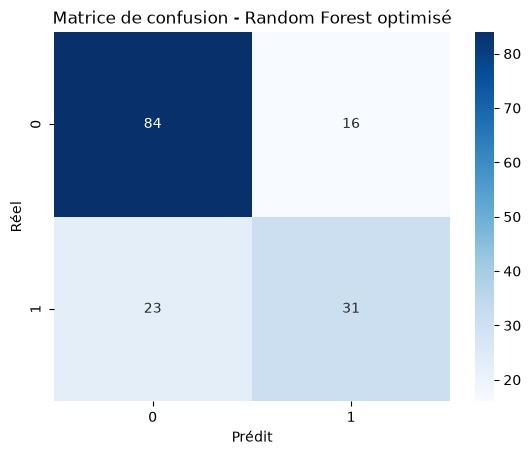

0.6138613861386139

In [48]:
# Hyperparameter tuning for Random Forest
param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5, 10],
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid, cv=5, scoring="f1", n_jobs=-1
)
grid.fit(X_train_scaled, y_train)

print("Meilleurs paramètres :", grid.best_params_)
print("Meilleur score CV :", grid.best_score_)

best_model = grid.best_estimator_
evaluer(best_model, "Random Forest optimisé")

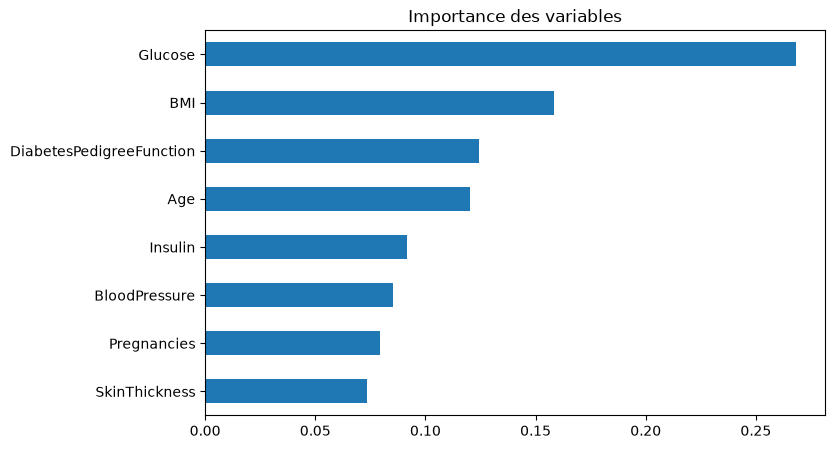

/home/avande/diabete_predictions/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


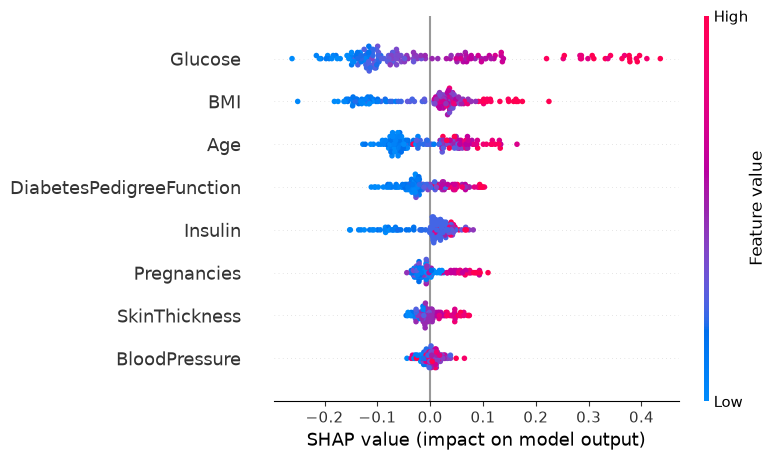

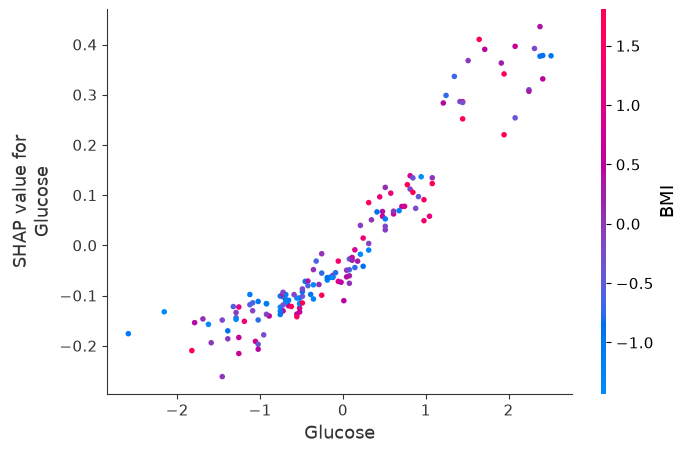

In [ ]:
# Importance des variables
importances = pd.Series(best_model.feature_importances_, index=X.columns)
importances.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("Importance des variables")
plt.show()
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test_scaled)

X_test_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# Selon la version de shap, shap_values peut être une liste (une par classe)
# ou un tableau 3D. On prend la classe 1 (diabète).
if isinstance(shap_values, list):
    sv = shap_values[1]
elif shap_values.ndim == 3:
    sv = shap_values[:, :, 1]
else:
    sv = shap_values

shap.summary_plot(sv, X_test_df)

# Dépendance pour la variable la plus importante
top_feature = importances.idxmax()
shap.dependence_plot(top_feature, sv, X_test_df)

In [ ]:
# model saving
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(**grid.best_params_, random_state=42)),
])

# Données brutes (X_train / X_test non transformés, avec les NaN)
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

joblib.dump(pipeline, "pipeline.joblib")

              precision    recall  f1-score   support

           0       0.79      0.84      0.81       100
           1       0.66      0.57      0.61        54

    accuracy                           0.75       154
   macro avg       0.72      0.71      0.71       154
weighted avg       0.74      0.75      0.74       154



['pipeline.joblib']